# 05 · Espaço para crescer e próximos meses

Os notebooks anteriores mostraram que a Olist cresce (02), que o atraso derruba a nota e a recompra (03) e que o atraso se concentra no transporte para o Rio de Janeiro e o Nordeste (04). Um investidor pergunta o passo seguinte:

> **Onde ainda há espaço para crescer e o que esperar dos próximos meses?**

A primeira parte usa um dado externo: quantas pessoas moravam em cada estado em 2018, segundo o IBGE. A conta é simples: quantos pedidos a Olist faz **a cada 100 mil moradores**. Onde esse número é baixo, há gente que ainda não compra.

A segunda parte faz uma previsão simples do valor vendido por mês até o fim de 2018, usando só média e desvio padrão.

## 8.1 Leitura dos dados

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

AZUL, LARANJA, CINZA = '#2a78d6', '#eb6834', '#a3a29d'
plt.rcParams.update({
    'figure.figsize': (10, 4), 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#a3a29d', 'axes.titlesize': 12, 'axes.titleweight': 'bold',
    'axes.titlelocation': 'left', 'axes.grid': True, 'axes.axisbelow': True,
    'grid.color': '#e6e5e0', 'grid.linewidth': 0.8, 'axes.grid.axis': 'y',
})

pedidos = pd.read_csv('../data/processed/pedidos.csv')
populacao = pd.read_csv('../data/external/populacao_uf_2018_ibge.csv')

print('Pedidos:', pedidos.shape)
print('Estados na tabela do IBGE:', populacao['uf'].nunique())
print(f"Moradores do Brasil em 2018: {populacao['populacao_2018'].sum():,}")
populacao.head()

Pedidos: (99441, 31)
Estados na tabela do IBGE: 27
Moradores do Brasil em 2018: 208,494,900


,uf,estado,regiao,populacao_2018
0,RO,Rondônia,Norte,1757589
1,AC,Acre,Norte,869265
2,AM,Amazonas,Norte,4080611
3,RR,Roraima,Norte,576568
4,PA,Pará,Norte,8513497


A tabela do IBGE tem os 27 estados e soma **208,5 milhões de moradores**, a estimativa oficial para 2018 (tabela 6579 do SIDRA). São todas as pessoas que moram no estado, clientes da Olist ou não. O ano está dentro do recorte da base (jan/2017 a ago/2018).

Para contar os pedidos, uso as regras do notebook 02: só o recorte e só vendas válidas (sem cancelados e indisponíveis). Para o atraso, só pedidos entregues, como no notebook 03.

In [2]:
vendas = pedidos[pedidos['no_recorte'] & pedidos['venda_valida']]
entregues = pedidos[pedidos['no_recorte'] & pedidos['entregue']]

por_uf = populacao.set_index('uf')
por_uf['pedidos'] = vendas.groupby('uf_cliente').size()
por_uf['pct_atraso'] = entregues.groupby('uf_cliente')['atrasado'].mean()
por_uf['pedidos_100mil_moradores'] = por_uf['pedidos'] / por_uf['populacao_2018'] * 100_000

print(f"Pedidos válidos no recorte: {len(vendas):,}")
print('Estados sem pedidos:', por_uf['pedidos'].isna().sum())

Pedidos válidos no recorte: 97,905
Estados sem pedidos: 0


**97.905 pedidos** válidos, os mesmos do notebook 02, e todos os estados têm pedidos.

## 8.2 A Olist vende onde as pessoas estão?

Para cada região, comparo duas fatias:
- % dos moradores do Brasil: de cada 100 pessoas que moram no país, quantas moram na região.
- % dos pedidos: de cada 100 pedidos da Olist, quantos foram para a região.

E calculo os **pedidos a cada 100 mil moradores**: pedidos da região ÷ moradores da região × 100 mil. Uso "a cada 100 mil" porque por pessoa o número fica minúsculo.

**Hipótese:** se a Olist vendesse por igual no país, as duas fatias seriam parecidas em todas as regiões.

              pct_moradores  pct_pedidos  pedidos_100mil_moradores  pct_atraso
regiao                                                                        
Sudeste               0.421        0.686                    76.553       0.061
Nordeste              0.272        0.095                    16.335       0.128
Sul                   0.143        0.142                    46.874       0.059
Norte                 0.087        0.019                    10.054       0.086
Centro-Oeste          0.077        0.058                    35.509       0.065


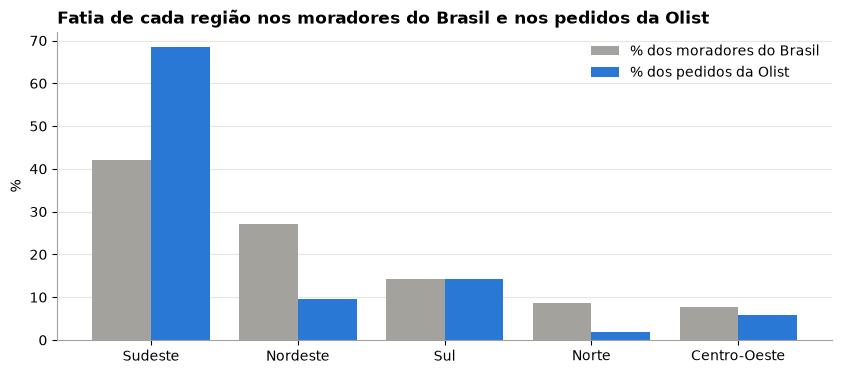

In [3]:
por_regiao = por_uf.groupby('regiao').agg(moradores=('populacao_2018', 'sum'), pedidos=('pedidos', 'sum'))
por_regiao['pct_moradores'] = por_regiao['moradores'] / por_regiao['moradores'].sum()
por_regiao['pct_pedidos'] = por_regiao['pedidos'] / por_regiao['pedidos'].sum()
por_regiao['pedidos_100mil_moradores'] = por_regiao['pedidos'] / por_regiao['moradores'] * 100_000
regiao_entregues = entregues.merge(populacao[['uf', 'regiao']], left_on='uf_cliente', right_on='uf')
por_regiao['pct_atraso'] = regiao_entregues.groupby('regiao')['atrasado'].mean()
por_regiao = por_regiao.sort_values('pct_moradores', ascending=False)

print(por_regiao[['pct_moradores', 'pct_pedidos', 'pedidos_100mil_moradores', 'pct_atraso']].round(3))

posicao = range(len(por_regiao))
plt.figure()
plt.bar([p - 0.2 for p in posicao], por_regiao['pct_moradores'] * 100, width=0.4, color=CINZA, label='% dos moradores do Brasil')
plt.bar([p + 0.2 for p in posicao], por_regiao['pct_pedidos'] * 100, width=0.4, color=AZUL, label='% dos pedidos da Olist')
plt.xticks(list(posicao), por_regiao.index)
plt.title('Fatia de cada região nos moradores do Brasil e nos pedidos da Olist')
plt.ylabel('%')
plt.legend(frameon=False)
plt.show()

- O Sudeste tem 42% dos moradores do Brasil e 69% dos pedidos: 77 pedidos a cada 100 mil moradores.
- O Sul é a única região equilibrada (14% dos moradores, 14% dos pedidos).
- O Nordeste tem **27% dos moradores do Brasil** e só **9,5% dos pedidos**: compra pouco para o tamanho que tem. São 16 pedidos a cada 100 mil moradores, quase cinco vezes menos que o Sudeste. E é a região com **mais atraso: 12,8%**, o dobro do Sudeste (6,1%).
- O Norte compra ainda menos (10 pedidos a cada 100 mil moradores), com atraso de 8,6%.

A hipótese não se sustenta: a Olist não vende onde as pessoas estão. O Nordeste, com 57 milhões de moradores, é o maior grupo que quase não compra, e é também onde a entrega mais falha.

## 8.3 Pedidos a cada 100 mil moradores, por estado

O mesmo cálculo, agora para cada estado. Em laranja, os estados com atraso acima de 10% (o mesmo corte do notebook 04).

          regiao  pedidos  pedidos_100mil_moradores  pct_atraso
uf                                                             
SP       Sudeste    41021                    90.079       0.045
RJ       Sudeste    12654                    73.741       0.121
DF  Centro-Oeste     2114                    71.066       0.057
MG       Sudeste    11457                    54.452       0.046
SC           Sul     3590                    50.739       0.082
ES       Sudeste     2014                    50.700       0.107
RS           Sul     5395                    47.619       0.061
PR           Sul     4962                    43.722       0.041
GO  Centro-Oeste     1990                    28.752       0.066
MT  Centro-Oeste      900                    26.148       0.060
MS  Centro-Oeste      708                    25.764       0.097
BA      Nordeste     3340                    22.548       0.122
TO         Norte      278                    17.875       0.099
PE      Nordeste     1636               

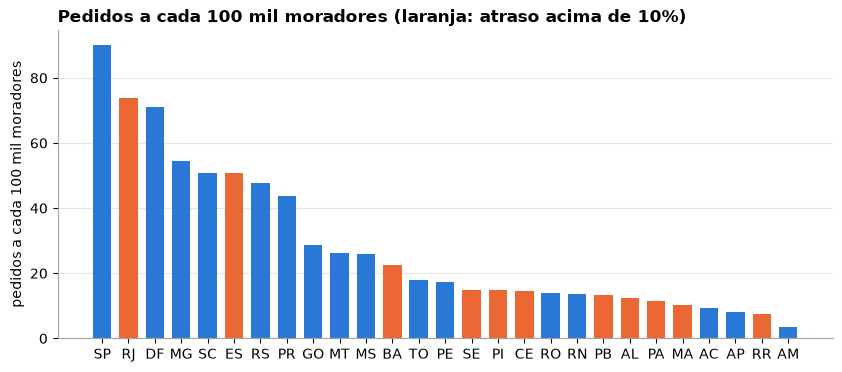

In [4]:
por_uf = por_uf.sort_values('pedidos_100mil_moradores', ascending=False)
print(por_uf[['regiao', 'pedidos', 'pedidos_100mil_moradores', 'pct_atraso']].round(3))

cores = [LARANJA if p > 0.10 else AZUL for p in por_uf['pct_atraso']]
plt.figure()
plt.bar(por_uf.index, por_uf['pedidos_100mil_moradores'], color=cores, width=0.7)
plt.title('Pedidos a cada 100 mil moradores (laranja: atraso acima de 10%)')
plt.ylabel('pedidos a cada 100 mil moradores')
plt.show()

- Os estados que mais compram são **SP (90 pedidos a cada 100 mil moradores)**, **RJ (74)** e **DF (71)**.
- No fim da lista estão os estados do Norte e do Nordeste: o Maranhão faz 10 pedidos a cada 100 mil moradores e atrasa 17,5%; Alagoas, 12 e 21,5%.
- Cuidado com a conclusão: comprar pouco não vem só do atraso. O Amazonas compra menos que todos (3,6) e quase não atrasa (2,8%); o Rio de Janeiro compra muito e atrasa 12%. Renda, acesso à internet e distância dos vendedores também pesam, e a base não permite separar essas causas.

O que dá para afirmar: o Nordeste é o maior mercado pouco atendido pela Olist e é onde a entrega mais falha. Como o notebook 03 mostrou que o atraso derruba a nota e a recompra, crescer no Nordeste sem corrigir a logística seria trazer clientes para uma experiência ruim. Corrigir as rotas para o Nordeste é condição para crescer lá.

## 9.1 Como o valor vendido evoluiu mês a mês?

Para prever, primeiro olho o passado. O notebook 02 mostrou que jan-ago/2018 vendeu 140% a mais que jan-ago/2017. **Hipótese:** se esse ritmo continua, cada mês de 2018 vende bem mais que o anterior. Para testar, somo o valor vendido (GMV) de cada mês e comparo cada mês de 2018 com o mesmo mês de 2017.

Valor vendido por mês (R$ milhões) e crescimento contra o mesmo mês de 2017
     2017  2018  crescimento_%
jan  0.14  1.10         704.65
fev  0.28  0.98         245.42
mar  0.43  1.15         170.82
abr  0.41  1.16         184.90
mai  0.58  1.15          96.61
jun  0.50  1.02         104.22
jul  0.58  1.04          79.66
ago  0.66  1.00          50.62


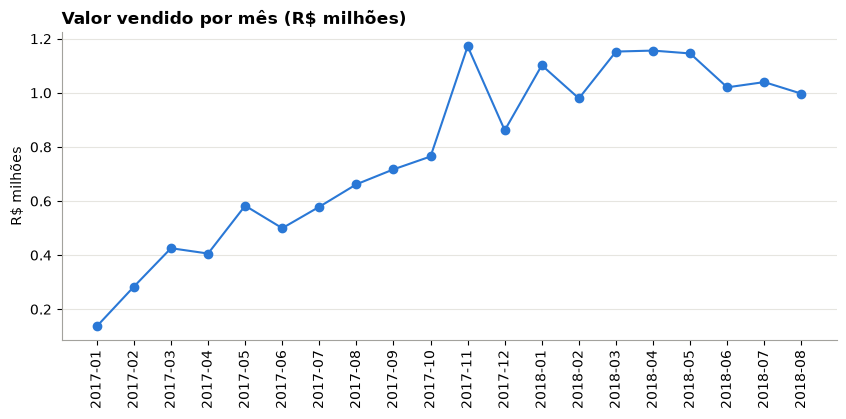

In [5]:
mensal = vendas.groupby('mes').agg(pedidos=('order_id', 'size'), valor_vendido=('receita', 'sum'))
mensal['valor_mi'] = mensal['valor_vendido'] / 1_000_000

meses = ['jan', 'fev', 'mar', 'abr', 'mai', 'jun', 'jul', 'ago']
comparacao = pd.DataFrame({'2017': mensal.loc['2017-01':'2017-08', 'valor_mi'].values,
                           '2018': mensal.loc['2018-01':'2018-08', 'valor_mi'].values}, index=meses)
comparacao['crescimento_%'] = (comparacao['2018'] / comparacao['2017'] - 1) * 100
print('Valor vendido por mês (R$ milhões) e crescimento contra o mesmo mês de 2017')
print(comparacao.round(2))

plt.figure()
plt.plot(mensal.index, mensal['valor_mi'], color=AZUL, marker='o')
plt.title('Valor vendido por mês (R$ milhões)')
plt.ylabel('R$ milhões')
plt.xticks(rotation=90)
plt.show()

- Em 2017 a Olist cresceu quase todo mês: de R\$ 0,14 mi em janeiro para R\$ 0,86 mi em dezembro, com um pico de R\$ 1,17 mi em novembro (Black Friday).
- Em 2018 as vendas param de subir: os meses ficam entre R\$ 0,98 mi e R\$ 1,16 mi.
- O crescimento contra o mesmo mês de 2017 cai mês a mês: +705% em janeiro, +97% em maio, +80% em julho.

A hipótese não se sustenta: 2018 é um ano de estabilidade, não de crescimento acelerado. Os 140% do notebook 02 vêm da subida ao longo de 2017. Para o investidor, isso muda a leitura: a fase de crescimento rápido parece ter terminado e, para voltar a crescer, a Olist precisa de algo novo, como novos mercados (o Nordeste do item 8.2) ou mais recompra (notebook 03).

Agosto/2018 aparece como o menor mês do ano. Antes de usá-lo na previsão, vale conferir se ele está completo.

## 9.2 O último mês da base está completo?

O notebook 01 indicou que a base pública parece uma seleção, sem pedidos que ainda estavam em andamento. Se for isso, os últimos dias da base teriam menos pedidos do que a Olist realmente vendeu. **Hipótese:** o fim de agosto/2018 está incompleto. Para testar, conto os pedidos por dia de compra desde julho.

Média de pedidos por dia em julho: 201

Últimos dias da base:
dia
2018-08-20    252
2018-08-21    239
2018-08-22    186
2018-08-23    142
2018-08-24     97
2018-08-25     69
2018-08-26     73
2018-08-27     66
2018-08-28     39
2018-08-29     11
dtype: int64


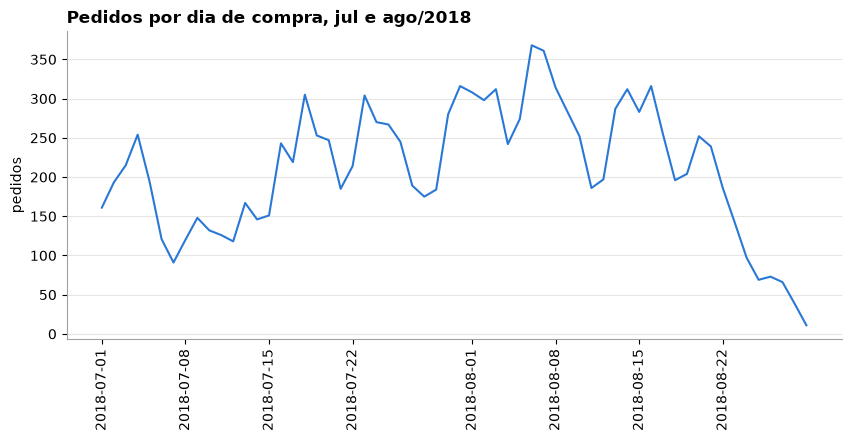

In [6]:
por_dia = vendas[vendas['mes'].isin(['2018-07', '2018-08'])].copy()
por_dia['dia'] = pd.to_datetime(por_dia['order_purchase_timestamp']).dt.date
por_dia = por_dia.groupby('dia').size()

print('Média de pedidos por dia em julho:', round(por_dia.loc[:pd.Timestamp('2018-07-31').date()].mean()))
print('\nÚltimos dias da base:')
print(por_dia.tail(10))

plt.figure()
plt.plot(por_dia.index, por_dia.values, color=AZUL)
plt.title('Pedidos por dia de compra, jul e ago/2018')
plt.ylabel('pedidos')
plt.xticks(rotation=90)
plt.show()

- Em julho a média é de 201 pedidos por dia, e até 21 de agosto o ritmo segue parecido (entre 186 e 368 por dia).
- A partir de 22 de agosto o número despenca: 142 no dia 23, 66 no dia 27 e só 11 no dia 29, o último dia com pedidos válidos.

A hipótese se sustenta: **agosto/2018 está incompleto**. A queda não é da Olist; é a base que perde os pedidos dos últimos dias. Isso corrige um ponto do notebook 01, que tratava agosto como mês completo.

**Decisão:** a previsão usa jan a jul/2018. As outras análises (atraso, nota, estados) seguem com o recorte do notebook 01, porque os pedidos de agosto que estão na base são válidos. O crescimento de 140% do notebook 02 fica um pouco subestimado: sem agosto, jan-jul/2018 vende 161% a mais que jan-jul/2017.

In [7]:
jan_jul_2017 = mensal.loc['2017-01':'2017-07', 'valor_mi'].sum()
jan_jul_2018 = mensal.loc['2018-01':'2018-07', 'valor_mi'].sum()
print(f'Jan-jul/2017: R$ {jan_jul_2017:.2f} mi | jan-jul/2018: R$ {jan_jul_2018:.2f} mi | crescimento: {(jan_jul_2018 / jan_jul_2017 - 1) * 100:.0f}%')

Jan-jul/2017: R$ 2.91 mi | jan-jul/2018: R$ 7.60 mi | crescimento: 161%


## 9.3 Previsão de ago a dez/2018

Como 2018 está estável, a previsão mais honesta é a mais simples: os próximos meses devem ficar perto da média de 2018. Uso só medidas das aulas de tendência central e dispersão:
- Previsão: média de jan a jul/2018.
- Faixa: do menor ao maior mês de jan a jul/2018 (a amplitude). A faixa de média ± 1 desvio padrão deixava metade dos meses de fora, estreita demais para prometer a um investidor.
- **Coeficiente de variação (CV):** desvio padrão ÷ média. Quanto menor, mais previsível o mês.

Antes de prever o futuro, testo o método no passado: com só jan a abr/2018, eu teria acertado mai a jul?

In [8]:
teste_base = mensal.loc['2018-01':'2018-04', 'valor_mi']
teste_real = mensal.loc['2018-05':'2018-07', 'valor_mi']
teste = pd.DataFrame({'previsto': teste_base.mean(), 'real': teste_real})
teste['erro_%'] = (teste['real'] / teste['previsto'] - 1) * 100
teste['dentro_da_faixa'] = teste['real'].between(teste_base.min(), teste_base.max())
print(f'Teste: previsão de R$ {teste_base.mean():.2f} mi por mês, faixa de R$ {teste_base.min():.2f} a {teste_base.max():.2f} mi')
print(teste.round(2))

Teste: previsão de R$ 1.10 mi por mês, faixa de R$ 0.98 a 1.16 mi
         previsto  real  erro_%  dentro_da_faixa
mes                                             
2018-05       1.1  1.15    4.38             True
2018-06       1.1  1.02   -7.03             True
2018-07       1.1  1.04   -5.27             True


O método passa no teste: os três meses ficam dentro da faixa, com erro entre -7% e +4%. Agora aplico o mesmo método com jan a jul/2018.

Média mensal de jan a jul/2018: R$ 1.09 mi
Desvio padrão: R$ 0.07 mi
Coeficiente de variação: 6.6%
Faixa prevista por mês: R$ 0.98 mi a R$ 1.16 mi


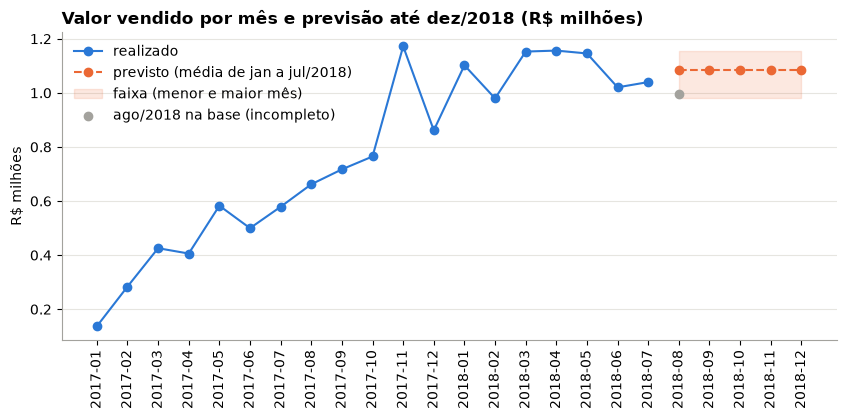

In [9]:
base_2018 = mensal.loc['2018-01':'2018-07', 'valor_mi']
media = base_2018.mean()
desvio = base_2018.std()
menor, maior = base_2018.min(), base_2018.max()

print(f'Média mensal de jan a jul/2018: R$ {media:.2f} mi')
print(f'Desvio padrão: R$ {desvio:.2f} mi')
print(f'Coeficiente de variação: {desvio / media * 100:.1f}%')
print(f'Faixa prevista por mês: R$ {menor:.2f} mi a R$ {maior:.2f} mi')

completos = mensal.loc[:'2018-07']
futuro = ['2018-08', '2018-09', '2018-10', '2018-11', '2018-12']
plt.figure()
plt.plot(completos.index, completos['valor_mi'], color=AZUL, marker='o', label='realizado')
plt.plot(futuro, [media] * 5, color=LARANJA, marker='o', linestyle='--', label='previsto (média de jan a jul/2018)')
plt.fill_between(futuro, menor, maior, color=LARANJA, alpha=0.15, label='faixa (menor e maior mês)')
plt.scatter(['2018-08'], [mensal.loc['2018-08', 'valor_mi']], color=CINZA, zorder=3, label='ago/2018 na base (incompleto)')
plt.title('Valor vendido por mês e previsão até dez/2018 (R$ milhões)')
plt.ylabel('R$ milhões')
plt.xticks(rotation=90)
plt.legend(frameon=False)
plt.show()

- Os meses de 2018 variam pouco: média de R\$ 1,09 mi, desvio padrão de R\$ 0,07 mi e CV de 6,6%. Para comparar, o prazo de entrega tem CV de 76% (notebook 03): as vendas são muito mais previsíveis que a entrega.
- Previsão: mantido o ritmo de 2018, a Olist deve vender cerca de **R\$ 1,09 mi por mês** de agosto a dezembro, entre R\$ 0,98 mi e R\$ 1,16 mi. Novembro é a exceção (item 9.4).

A previsão vale se nada mudar: sem nova estratégia, sem choque na economia. Ela não tenta adivinhar detalhes; diz apenas que, pelo comportamento de 2018, não há sinal de queda nem de nova aceleração.

## 9.4 E a Black Friday?

Novembro de 2017 foi o mês fora da curva do gráfico: a Black Friday caiu em 24/11/2017 (fonte em docs/fontes_externas.md). **Hipótese:** novembro de 2018 também deve vender acima da média. Para estimar quanto, comparo nov/2017 com a média dos meses vizinhos (out e dez/2017) e aplico esse aumento à média de 2018.

Como mais pedidos pressionam a entrega, também olho o atraso e a nota de set/2017 a abr/2018.

In [10]:
novembro_2017 = mensal.loc['2017-11', 'valor_mi']
vizinhos_2017 = mensal.loc[['2017-10', '2017-12'], 'valor_mi'].mean()
efeito = novembro_2017 / vizinhos_2017 - 1

print(f'Nov/2017: R$ {novembro_2017:.2f} mi | média de out e dez/2017: R$ {vizinhos_2017:.2f} mi')
print(f'Efeito da Black Friday: +{efeito * 100:.0f}%')
print(f'Nov/2018 estimado: R$ {media * (1 + efeito):.2f} mi')

em_volta = entregues.groupby('mes').agg(pct_atraso=('atrasado', 'mean'), nota_media=('nota', 'mean'))
print('\nAtraso e nota dos pedidos entregues, por mês de compra')
print(em_volta.loc['2017-09':'2018-04'].round(3))

Nov/2017: R$ 1.17 mi | média de out e dez/2017: R$ 0.81 mi
Efeito da Black Friday: +44%
Nov/2018 estimado: R$ 1.56 mi

Atraso e nota dos pedidos entregues, por mês de compra
         pct_atraso  nota_media
mes                            
2017-09       0.044       4.268
2017-10       0.042       4.205
2017-11       0.124       3.989
2017-12       0.075       4.088
2018-01       0.057       4.109
2018-02       0.141       3.881
2018-03       0.190       3.813
2018-04       0.045       4.206


- Novembro de 2017 vendeu 44% a mais que a média de outubro e dezembro. Aplicando o mesmo aumento à média de 2018, **novembro de 2018 ficaria em torno de R\$ 1,56 mi**, o melhor mês do ano.
- Cuidado: a base tem uma única Black Friday, então o número é uma estimativa grosseira. Serve para dizer que novembro deve ser o maior mês, não para cravar o valor.
- O ponto mais importante: em novembro de 2017 o atraso triplicou (de 4,2% em outubro para 12,4%) e a nota média caiu de 4,2 para 4,0. O pico de vendas sobrecarregou a entrega.
- Fevereiro e março de 2018 também tiveram atraso alto (14% e 19%) e nota baixa, sem pico de vendas. A base não mostra a causa.

Leitura: a Black Friday traz o maior volume do ano e também o maior risco para a entrega e para a nota. Preparar a logística antes de novembro (transportadoras com capacidade extra e prazo prometido mais folgado nas rotas críticas) protege justamente o mês que mais vende.

## Resumo de espaço para crescer e próximos meses

| # | Verificação | O que os dados mostraram | Decisão |
|---|---|---|---|
| 8.1 | Dado externo | população de 2018 do IBGE, 27 estados, 208,5 milhões de moradores | data/external/populacao_uf_2018_ibge.csv |
| 8.2 | Fatia por região | Nordeste com 27% dos moradores e 9,5% dos pedidos (16 a cada 100 mil moradores, contra 77 no Sudeste) e 12,8% de atraso | Nordeste como mercado pouco atendido |
| 8.3 | Por estado | SP, RJ e DF compram mais; Norte e Nordeste menos; o Amazonas compra pouco e quase não atrasa | atraso não é a única causa de comprar pouco |
| 9.1 | Evolução mensal | 2017 cresce, 2018 estável entre R\$ 0,98 e 1,16 mi; crescimento contra 2017 cai de +705% para +80% | 2018 como base da previsão |
| 9.2 | Fim da base | pedidos despencam a partir de 22/08/2018 | agosto incompleto; previsão com jan a jul; jan-jul cresce 161% |
| 9.3 | Previsão | teste em mai a jul acertou a faixa (erro de -7% a +4%); média de R\$ 1,09 mi, CV de 6,6% | cerca de R\$ 1,09 mi por mês, entre R\$ 0,98 e 1,16 mi |
| 9.4 | Black Friday | nov/2017 vendeu 44% acima dos vizinhos e o atraso triplicou (12,4%) | nov/2018 em torno de R\$ 1,56 mi; risco logístico |

**Resposta à pergunta:**
- **Espaço para crescer:** o Nordeste, com 57 milhões de moradores e pouca compra. Mas é onde a entrega mais falha, então crescer lá depende de corrigir a logística primeiro.
- Próximos meses: estabilidade, em torno de R\$ 1,09 mi por mês, com novembro mais forte. A Black Friday é o mês de maior venda e de maior risco de atraso: preparar a entrega antes dela é a ação mais urgente.